# Imports and load data

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
from roaring_landmask import RoaringLandmask

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [2]:
# Helper
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


## Load data (Only bulk_data_df important)

In [3]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_list=[]
for year in range(2007,2009):
    # if year ==2009:
    #     continue
    bulk_data_df_list.append(pd.read_parquet(os.path.join(BULK_PATH,f"glaciations_with_bulk_data_V3_1_{year}.parquet")))

bulk_data_df = pd.concat(bulk_data_df_list, ignore_index=True)

# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))


Filter rows with no measurements (Cehck why are there such???)

In [4]:
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]

## Split cells by pass

In [5]:
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]

In [6]:
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split = bulk_data_df_split[(bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & ((bulk_data_df_split["avg_ctt"]-273.15)>-36))]
bulk_data_df_split


,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_height_means_m,ddc_cloud_top_height_means_m,ddc_cloud_top_temp_means_K,ext_bulk_means,temp_bulk_means,Z_bulk_means,cph_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m
0,46752,30,0.708242,20,22,True,0.004607,"[1.4164830446243286, 1.4164830446243286]",1.416483,0.50,...,"[6.9012494, 6.785952, 6.186, 9.016042, 8.94275...",6.901249,233.542358,"[0.000180145, 6.943065e-05, 2.6901973e-05, 4.1...","[233.54236, 233.75578, 236.44174, 221.41113, 2...","[-30.940184, -28.647013, -24.271124, -18.5519,...","[1.3557808, 1.3128881, 1.2119192, 1.2739899, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
1,70032,75,0.716289,46,51,True,0.090226,"[0.5730308055877685, 0.5730308055877685, 0.573...",0.573031,1.25,...,"[6.514615, 6.481074, 6.3637276, 6.1866965, 5.8...",6.514615,237.852280,"[3.1734293e-05, 3.414293e-05, 3.5044148e-05, 3...","[237.85228, 238.24641, 239.17932, 240.26894, 2...","[-26.62337, -25.85598, -25.968014, -26.200325,...","[1.4737239, 1.4540604, 1.4773767, 1.7202992, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
2,70408,105,0.425825,22,29,False,0.167923,"[0.03942757613745672, 0.040755974553597286, 0....",0.303342,1.75,...,"[4.3713665, 4.290206, 4.134128, 3.9109821, 3.4...",4.371367,259.799683,"[6.136837e-05, 6.236592e-05, 5.5882938e-05, 3....","[259.79968, 259.86838, 260.40674, 261.48206, 2...","[-22.21927, -20.380392, -20.995928, -22.083258...","[1.6056547, 1.7242559, 1.8555673, 1.88125, 1.9...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
3,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[4.298905, 4.1822667, 4.063569, 3.9442232, 3.8...",4.298905,258.880188,"[0.0020007854, 0.0030006275, 0.003652379, 0.00...","[258.8802, 259.44913, 259.94424, 260.39053, 26...","[-15.76357, -12.826077, -10.580673, -8.728764,...","[1.9606113, 1.9772339, 1.9966713, 1.9979339, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
4,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[2.9155383, 3.06, 2.9423077, 2.8223078, 2.2160...",2.915538,257.667480,"[6.4273727e-06, 9.508473e-06, 1.4556285e-05, 1...","[257.66748, 256.61264, 257.30948, 257.98065, 2...","[-30.644104, -28.91097, -28.187925, -27.067188...","[1.1166801, 1.0714285, 1.0934066, 1.1692307, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4748,3949837,45,0.461147,1,4,True,0.027467,"[0.6148629188537598, 0.6148629188537598, 0.614...",0.614863,0.75,...,"[5.404926, 5.294039, 5.1397033, 5.0050373, 4.9...",5.404926,233.715393,"[0.00018203132, 0.00017029994, 0.00017904138, ...","[233.7154, 234.34567, 235.34581, 236.21667, 23...","[-25.036537, -23.19391, -22.342916, -22.6214, ...","[1.9800822, 1.9770879, 1.9770663, 1.9929013, 1...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0..."
4749,3950174,300,0.592012,30,50,False,0.166797,"[0.38525419303509845, 0.44219361259278556, 0.4...",0.297695,5.00,...,"[3.923727, 3.8396645, 3.716255, 3.6004171, 3.4...",3.923727,244.055878,"[1.2572927e-05, 3.048536e-05, 4.4743065e-05, 5...","[244.05588, 244.42686, 244.8384, 245.17128, 24...","[-28.594433, -26.416636, -24.721663, -23.95

In [7]:
bulk_data_df_split.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'val_ice_frac_hist', 'val_ice_frac_std_hist', 'val_ice_frac_dev_hist',
       'val_pix_claas_if_hist', 'val_pix_claas_if_std_hist', 'val_cth_hist',
    

In [8]:
np.nanmax(np.concat(bulk_data_df_split["iwc_bulk_means"].to_numpy()))

np.float32(-25.417582)

In [9]:
((bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & (bulk_data_df_split["avg_ctt"]-273.15)>-36)).value_counts()

avg_ctt
True    4425
Name: count, dtype: int64

In [10]:
test_row=bulk_data_df_split.iloc[0]

## Stats by relative time

In [11]:
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)

In [12]:
def generate_stats_by_rel_time(df, mode="mean"):
    if mode == "mean":
        stats_by_rel_time = (
            df
            .groupby("rel_ind")
            .agg(
                n_hits=("iwc_bulk_means", "count"),

                mean_iwc_profile=(
                    "iwc_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_Z_profile=(
                    "Z_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_ext_profile=(
                    "ext_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_temp_profile=(
                    "temp_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                mean_bulk_height_profile_m=(
                    "bulk_level_offset_mid_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_top_m=(
                    "bulk_level_offset_top_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_bottom_m=(
                    "bulk_level_offset_bottom_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                dd_cth=(
                    "ddc_cloud_top_height_means_m",
                    "mean",
                ),

                sev_cth=(
                    "avg_cth",
                    "mean",
                ),

                dd_ctt=(
                    "ddc_cloud_top_temp_means_K",
                    "mean",
                ),

                mean_iwc_ct=(
                    "iwc_top_means",
                    "mean",
                ),

                sev_ctt=(
                    "avg_ctt",
                    "mean",
                ),
                
                mean_area_km=(
                    "avg_size[km]",
                    "mean",
                ),
                
            )
            .reset_index()
        )
    elif mode=="median":
        print("Calculating median")
        stats_by_rel_time = (
        df
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "median",
            ),

            sev_cth=(
                "avg_cth",
                "median",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "median",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "median",
            ),


            sev_ctt=(
                "avg_ctt",
                "median",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "median",
            ),
            
            )
            .reset_index()
        )
    else:
        raise ValueError("Set statistics 'MODE' to mean or median")
    stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15
    return stats_by_rel_time

# Prepare data

## Optical properties

In [78]:
def calculate_top_depth(row):
    tot_thickness = 0
    small_ext_counter = 0
    for j, ext in enumerate(row["ext_bulk_means"]):
        lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
        tot_thickness += lev_depth*ext
        if ext<2.0e-4:
            small_ext_counter+=1
        if tot_thickness>=0.2:
            # print(tot_thickness,j*120,small_ext_counter*120)
            return j*120
    return None
        
            
sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [79]:
(sample["ct_depth"]>600).value_counts()

ct_depth
False    69
True     31
Name: count, dtype: int64

In [80]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.2):
    tau = optical_depth_path(row)["tau"]
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    return top_idx*120

In [81]:
# Calculate total optical depth per cloud 
bulk_data_df_split["2km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4).all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_top_depth,axis=1)

In [82]:
bulk_data_df_split["ct_depth"].isna().value_counts()

ct_depth
False    3611
True      814
Name: count, dtype: int64

In [83]:
bulk_data_df_split.iloc[0]["val_cth_hist"]

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00,  3.39187398e+03, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00])

In [84]:
ALLOWED_CTH_DEV=1000
def _check_val_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    target_ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if not points_of_interest[target_ind]:
        print("weird")
        return False
    if type(row["cth_hist"]) == float:
            # N+=1
            return False
    cth_deviation = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # cth_deviations = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # if cth_deviations.size == 0:
    #     return False
    # mean_height_dev = cth_deviations.mean()  
    # if mean_height_dev > ALLOWED_CTH_DEV:
    #     return False
    if cth_deviation > ALLOWED_CTH_DEV:
        return False
    return True


In [85]:
bulk_data_df_split["val_seviri_coincidence"] = bulk_data_df_split.apply(_check_val_seviri_coincidence,axis=1)

In [86]:
bulk_data_df_split["val_seviri_coincidence"].value_counts()

val_seviri_coincidence
True     2772
False    1653
Name: count, dtype: int64

In [87]:
# print(np.argmax(optical_depth_path(bulk_data_filtered.iloc[0])["tau"]>0.3))
# print(optical_depth_path(bulk_data_filtered.iloc[0])["tau"])

<Figure size 700x500 with 0 Axes>

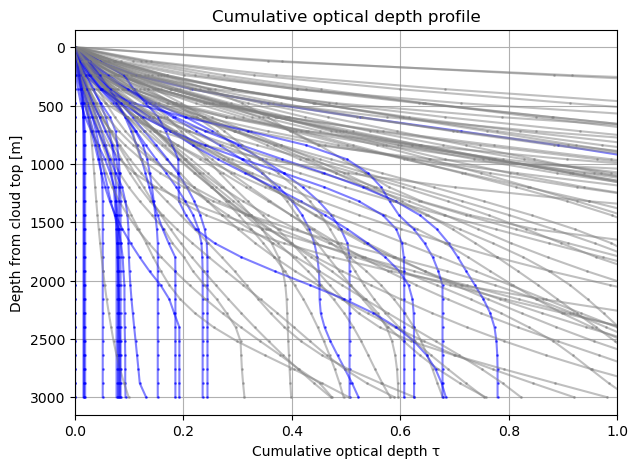

In [88]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt




plt.figure(figsize=(7, 5))

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path(row)

    if p is None:
        continue
    if ((p["tau"][1:]-p["tau"][:-1])<5*1e-4).any():
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="blue",
            markersize=1
        )
    else:
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="gray",
            markersize=1
        )



# plt.axvline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Cumulative optical depth τ")
plt.ylabel("Depth from cloud top [m]")
plt.title("Cumulative optical depth profile")
plt.grid(True)
plt.xlim(0, 1)

# Optional: depth increasing downward
plt.gca().invert_yaxis()

plt.show()

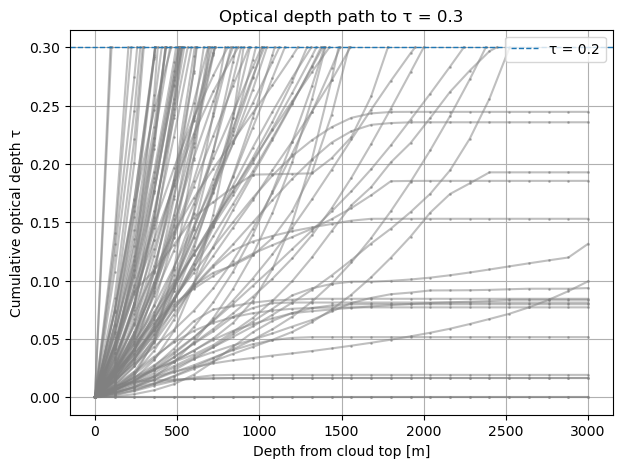

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

def optical_depth_path_to_03(row, tau_target=0.3):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext_profile = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    if len(dz) != len(ext_profile):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, "
            f"extinction has {len(ext_profile)} values"
        )

    tau = 0.0
    depth = 0.0

    depth_path = [0.0]
    tau_path = [0.0]

    for layer_dz, ext in zip(dz, ext_profile):
        layer_tau = layer_dz * ext

        # if tau_target is reached inside this layer, interpolate
        if tau + layer_tau >= tau_target:
            remaining_tau = tau_target - tau

            if ext > 0:
                depth_inside_layer = remaining_tau / ext
            else:
                depth_inside_layer = layer_dz

            depth += depth_inside_layer
            tau = tau_target

            depth_path.append(depth)
            tau_path.append(tau)
            break

        tau += layer_tau
        depth += layer_dz

        depth_path.append(depth)
        tau_path.append(tau)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path),
        "reached_03": tau >= tau_target
    }

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path_to_03(row, tau_target=0.3)

    if p is None:
        continue

    plt.plot(
        p["depth_m"],
        p["tau"],
        alpha=0.5,
        marker="o",
        color="gray",
        markersize=1
    )

plt.axhline(0.3, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Depth from cloud top [m]")
plt.ylabel("Cumulative optical depth τ")
plt.title("Optical depth path to τ = 0.3")
plt.grid(True)
plt.legend()
plt.show()

## Filter Data

In [90]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
    row["lat_hist"],
    row["lat_hist"]
),axis=1)
bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [91]:
# Filter only for clouds that survive after glaciation
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split["val_seviri_coincidence"]]
bulk_data_filtered = bulk_data_filtered[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["2km_cot"]>0.3]
# Select only one pass where 2 are available
bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
# Filter for cloud type
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# Remove clouds outside measurement boundaries
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_1688/2981631237.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  bulk_data_filtered = bulk_data_filtered[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]


,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,rel_ind,rel_time_min,2km_cot,continious_cloud,ct_depth,surface_type,is_maritime
3,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",35,525,8.703243,True,0.0,"[maritime, maritime, maritime, maritime, marit...",True
5,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",82,1230,1.340141,True,120.0,"[maritime, maritime, maritime, maritime, marit...",True
7,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-17,-255,4.366257,True,240.0,"[maritime, maritime, maritime, maritime, marit...",True
21,114140,270,0.539588,1,19,True,0.109781,"[0.11990847852494982, 0.11990847852494982, 0.1...",0.119908,4.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-6,-90,3.614178,True,240.0,"[maritime, maritime, maritime, maritime, marit...",False
23,116899,135,0.471595,70,79,True,0.098394,"[0.20959778626759848, 0.20959778626759848, 0.2...",0.209598,2.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",3,45,1.821105,True,360.0,"[land, land, land, land, land, land, land, lan...",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4712,3941134,1215,0.447553,5,86,True,0.091387,"[0.02210136548972424, 0.02210136548972424, 0.0...",0.022101,20.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-16,-240,0.640669,True,720.0,"[maritime, maritime, maritime, maritime, marit...",True
4721,3945220,630,0.497796,51,93,True,0.048022,"[0.04740909735361735, 0.04740909735361735, 0.0...",0.047409,10.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-77,-1155,2.036665,True,600.0,"[maritime, maritime, maritime, maritime, marit...",True
4724,3945224,750,0.455704,3,53,True,0.060309,"[0.03645628929138183, 0.03645628929138183, 0.0...",0.036456,12.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",55,825,1.433548,True,720.0,"[maritime, maritime, maritime, land, maritime,...",False
4731,3946060,2115,0.770868,0,141,False,0.176908,"[0.3326430852169193, 0.5987685460219256, 0.550...",0.085207,35.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-98,-1470,2.619733,True,480.0,"[maritime, maritime, maritime, maritime, marit...",True


## Z_Meas

In [92]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    iwc_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        iwc_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["iwc_bulk_means"].to_numpy())
        ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas, t_meas, ext_meas, iwc_meas

Z_meas, t_meas, ext_meas, iwc_meas = extract_bulk_samples_by_time(bulk_data_filtered)


# Significance statistics

## Plot Bulk

In [93]:
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,rel_ind,rel_time_min,2km_cot,continious_cloud,ct_depth,surface_type,is_maritime
3,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",35,525,8.703243,True,0.0,"[maritime, maritime, maritime, maritime, marit...",True
5,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",82,1230,1.340141,True,120.0,"[maritime, maritime, maritime, maritime, marit...",True
7,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-17,-255,4.366257,True,240.0,"[maritime, maritime, maritime, maritime, marit...",True
21,114140,270,0.539588,1,19,True,0.109781,"[0.11990847852494982, 0.11990847852494982, 0.1...",0.119908,4.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-6,-90,3.614178,True,240.0,"[maritime, maritime, maritime, maritime, marit...",False
23,116899,135,0.471595,70,79,True,0.098394,"[0.20959778626759848, 0.20959778626759848, 0.2...",0.209598,2.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",3,45,1.821105,True,360.0,"[land, land, land, land, land, land, land, lan...",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4712,3941134,1215,0.447553,5,86,True,0.091387,"[0.02210136548972424, 0.02210136548972424, 0.0...",0.022101,20.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-16,-240,0.640669,True,720.0,"[maritime, maritime, maritime, maritime, marit...",True
4721,3945220,630,0.497796,51,93,True,0.048022,"[0.04740909735361735, 0.04740909735361735, 0.0...",0.047409,10.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-77,-1155,2.036665,True,600.0,"[maritime, maritime, maritime, maritime, marit...",True
4724,3945224,750,0.455704,3,53,True,0.060309,"[0.03645628929138183, 0.03645628929138183, 0.0...",0.036456,12.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",55,825,1.433548,True,720.0,"[maritime, maritime, maritime, land, maritime,...",False
4731,3946060,2115,0.770868,0,141,False,0.176908,"[0.3326430852169193, 0.5987685460219256, 0.550...",0.085207,35.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-98,-1470,2.619733,True,480.0,"[maritime, maritime, maritime, maritime, marit...",True


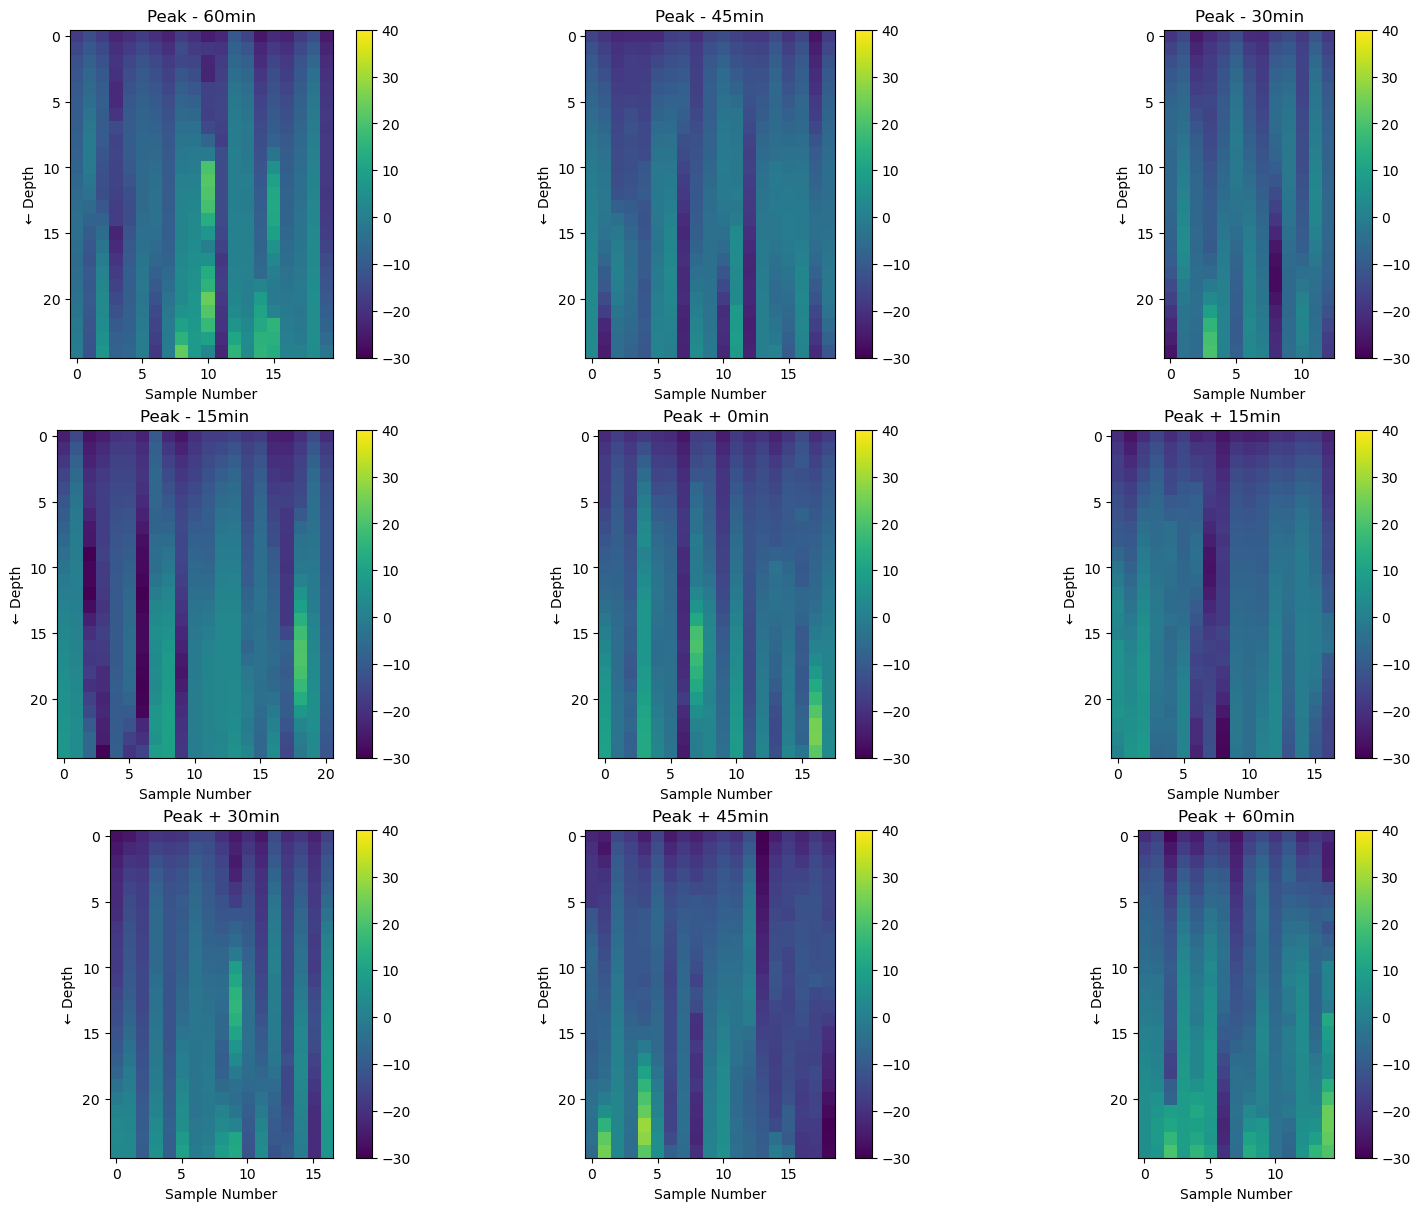

In [94]:
import numpy as np
import matplotlib.pyplot as plt

# Pre-defined index range
idx_range = range(-4, 5)   # example: Z_meas[0] ... Z_meas[5]

n = len(idx_range)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), constrained_layout=True)
axes = np.ravel(axes)

for ax, idx in zip(axes, idx_range):
    im = ax.imshow(Z_meas[idx].T, vmin=-30, vmax=40)
    if idx >= 0: label = f"Peak + {idx*15}min"
    else: label = f"Peak - {abs(idx*15)}min"
    ax.set_title(label)
    ax.set_ylabel("← Depth")
    ax.set_xlabel("Sample Number")
    fig.colorbar(im, ax=ax)

# Hide unused subplots
for ax in axes[n:]:
    ax.axis("off")

plt.show()

In [95]:
describe(bulk_data_filtered["Glaciation time [h]"])

{'count': 887,
 'mean': np.float64(5.680101465614431),
 'std': np.float64(5.774491128340495),
 'min': np.float64(0.25),
 '5%': np.float64(0.5),
 '25%': np.float64(1.75),
 '50%': np.float64(3.75),
 '75%': np.float64(7.25),
 '95%': np.float64(17.5),
 'max': np.float64(37.5)}

In [96]:
describe(bulk_data_filtered["track_length"]/pd.Timedelta(minutes=60))

{'count': 887,
 'mean': np.float64(15.847237880496055),
 'std': np.float64(11.782564829934007),
 'min': np.float64(1.0),
 '5%': np.float64(2.75),
 '25%': np.float64(7.5),
 '50%': np.float64(13.0),
 '75%': np.float64(21.5),
 '95%': np.float64(37.5),
 'max': np.float64(121.25)}

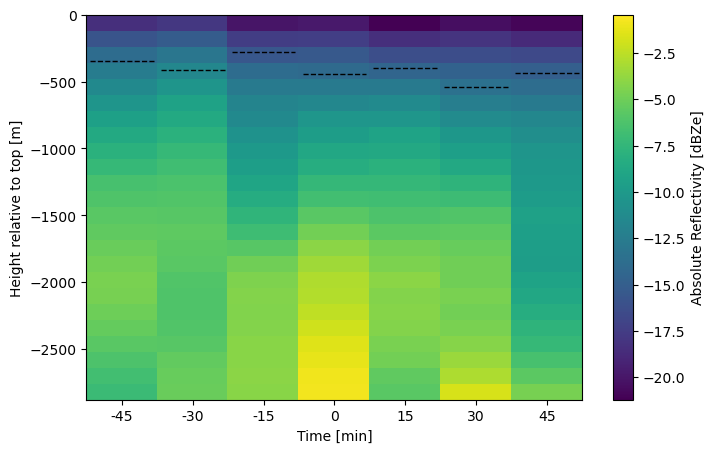

In [97]:

import numpy as np
import matplotlib.pyplot as plt

ind_range = [-3, 4]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
# or: 
y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))
ext_lev = np.zeros((len(inds)))

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)]=np.nan
    
    plot_map[:, col] = np.nanmean(dbZ,axis=0)
    ext_lev[col] = np.nanmean(ext_meas[ind])

level_means = np.tile(plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    plot_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        test_row["bulk_level_offset_bottom_m"][-1],
        0,
    ],
)

# plt.hlines(-(np.argmax(plot_map-level_means,axis=0)+0.5)*120,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)
plt.hlines(-ext_lev,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Absolute Reflectivity [dBZe]")
plt.show() 

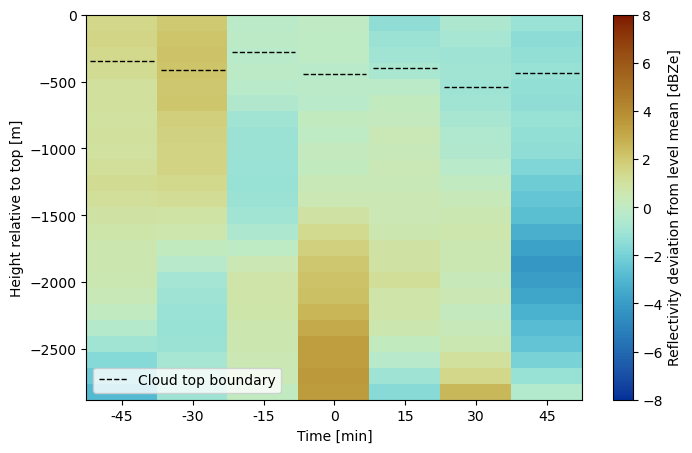

In [98]:

import numpy as np
import matplotlib.pyplot as plt

ind_range = [-3, 4]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
# or: 
y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)]=np.nan
    ext_lev[col] = np.nanmean(ext_meas[ind])
    plot_map[:, col] = np.nanmean(dbZ,axis=0)

level_means = np.tile(plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    plot_map-level_means,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        test_row["bulk_level_offset_bottom_m"][-1],
        0,
    ],
    cmap=cm.roma_r,
    vmax=8,
    vmin=-8
)
plt.hlines(-ext_lev,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1, label="Cloud top boundary")

# plt.hlines(-(np.argmax(plot_map-level_means,axis=0)+0.5)*120,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Reflectivity deviation from level mean [dBZe]")
plt.legend(loc="lower left")
plt.show() 

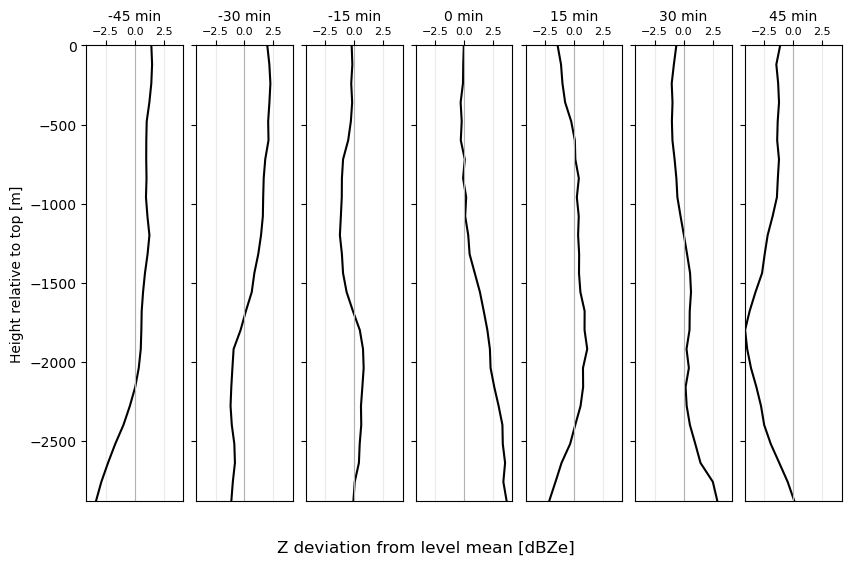

In [99]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-3, 4]
inds = np.arange(ind_range[0], ind_range[1])

y_levels = test_row["bulk_level_offset_top_m"]

plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)] = np.nan
    plot_map[:, col] = np.nanmean(dbZ, axis=0)

level_means = np.tile(
    plot_map.mean(axis=1)[:, np.newaxis],
    ind_range[1] - ind_range[0]
)

dev_map = plot_map - level_means


# Constant horizontal range for all vertical profiles
xmax = np.nanmax(np.abs(dev_map))
xlim = (-xmax, xmax)

fig, axes = plt.subplots(
    1,
    len(inds),
    figsize=(1.2 * len(inds), 5),
    sharey=True,
    constrained_layout=True
)

if len(inds) == 1:
    axes = [axes]

for ax, ind, profile in zip(axes, inds, dev_map.T):
    ax.plot(profile, y_levels, color="black", linewidth=1.5)

    max_i = np.nanargmax(profile)
    # ax.axhline(y_levels[max_i], linestyle="dashed", color="black", linewidth=1)

    ax.axvline(0, color="0.7", linewidth=0.8)

    # Same horizontal axis range everywhere
    ax.set_xlim(xlim)

    # Horizontal axes on top
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    ax.set_xlabel(f"{ind * 15} min")

    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])
fig.supxlabel("Z deviation from level mean [dBZe]", y=-0.1)

plt.show()

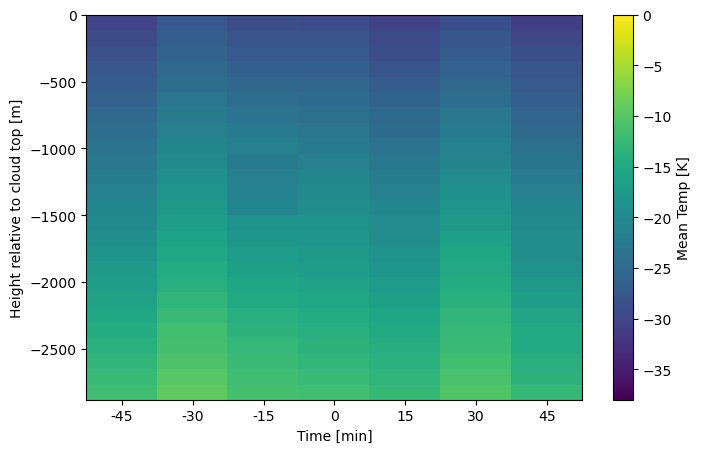

In [100]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-3, 4]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
y_levels = test_row["bulk_level_offset_top_m"]

temp_plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    
    temp_plot_map[:, col] = np.nanmean(t_meas[ind],axis=0)

level_means = np.tile(temp_plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    temp_plot_map-273.15,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-38,
    vmax=0
)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to cloud top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Mean Temp [K]")

plt.show()

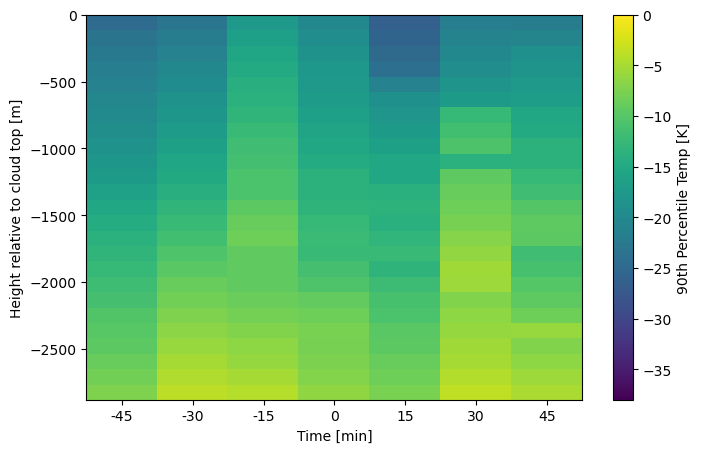

In [101]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-3, 4]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
y_levels = test_row["bulk_level_offset_top_m"]

temp_plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    
    temp_plot_map[:, col] = np.nanpercentile(t_meas[ind],90,axis=0)


plt.figure(figsize=(8, 5))

plt.imshow(
    temp_plot_map-273.15,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-38,
    vmax=0
)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to cloud top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="90th Percentile Temp [K]")

plt.show()

In [102]:
describe(Z_meas[-2])

{'count': 325,
 'mean': np.float32(-7.787545),
 'std': np.float32(7.215392),
 'min': np.float32(-28.032011),
 '5%': np.float32(-20.976597),
 '25%': np.float32(-12.193601),
 '50%': np.float32(-6.8259206),
 '75%': np.float32(-3.1954517),
 '95%': np.float32(2.0773866),
 'max': np.float32(19.935)}

In [103]:
from scipy.stats import t
import numpy as np
ind_range = [-3,4]
inds = np.arange(ind_range[0], ind_range[1])
y_levels = test_row["bulk_level_offset_top_m"]
n_levels = len(y_levels)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

dbZ_by_ind = {}

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)] = np.nan
    
    dbZ_by_ind[ind] = dbZ

    mean_map[:, col] = np.nanmean(dbZ, axis=0)
    std_map[:, col]  = np.nanstd(dbZ, axis=0, ddof=1)
    n_map[:, col]    = np.sum(np.isfinite(dbZ), axis=0)

sem_map = std_map / np.sqrt(n_map)

In [104]:
from scipy.stats import t
import numpy as np

def remove_outliers_iqr(x, k=1.5):
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]

def remove_outliers_trim(x, skip=2):
    x = x[np.isfinite(x)]
    x.sort()
    return x[skip:-skip]
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)

for j, ind in enumerate(inds):
    xmat = dbZ_by_ind[ind]

    other_inds = [k for k in inds if k != ind]
    ymat = np.vstack([dbZ_by_ind[k] for k in other_inds])

    for i in range(n_levels):
        x = xmat[:, i]
        y = ymat[:, i]

        x = x[np.isfinite(x)]
        y = y[np.isfinite(y)]

        n_y_raw = len(y)

        # Remove outliers only from y, as requested
        y = remove_outliers_iqr(y, k=1.5)
        x = remove_outliers_iqr(x, k=1.5)
        # y = remove_outliers_trim(y, skip=2)
        # x = remove_outliers_trim(x, skip=2)

        if len(x) < 2 or len(y) < 2:
            continue

        mx, my = np.mean(x), np.mean(y)
        vx, vy = np.var(x, ddof=1), np.var(y, ddof=1)
        nx, ny = len(x), len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = ((vx / nx) ** 2) / (nx - 1) + ((vy / ny) ** 2) / (ny - 1)

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den

        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = ny

/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_1688/3062615557.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower left")


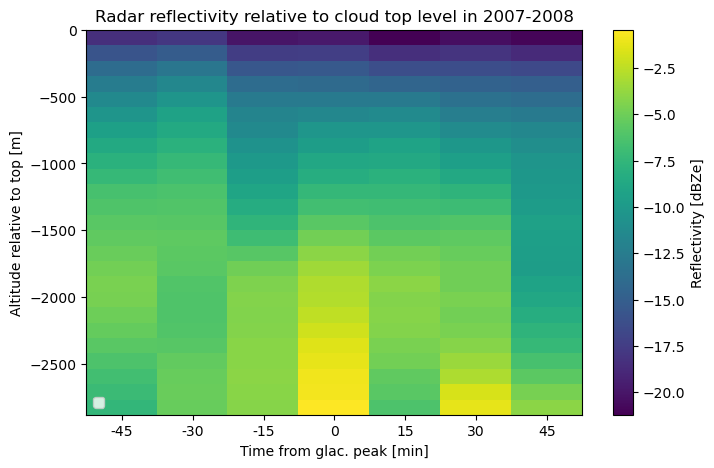

In [106]:
plt.figure(figsize=(8, 5))
sig_map = -np.log10(p_welch_map)
plt.imshow(
    mean_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    # vmin=-7,
    # vmax=7,
    # cmap=cm.roma_r
)
# plt.hlines(-ext_lev[1:-1],inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1, label="Cloud top boundary")

plt.xticks(inds, inds * 15)
plt.xlabel("Time from glac. peak [min]")
plt.ylabel("Altitude relative to top [m]")
plt.colorbar(label="Reflectivity [dBZe]")
plt.title("Radar reflectivity relative to cloud top level in 2007-2008")
plt.legend(loc="lower left")
plt.show()

/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_1688/927392533.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower left")


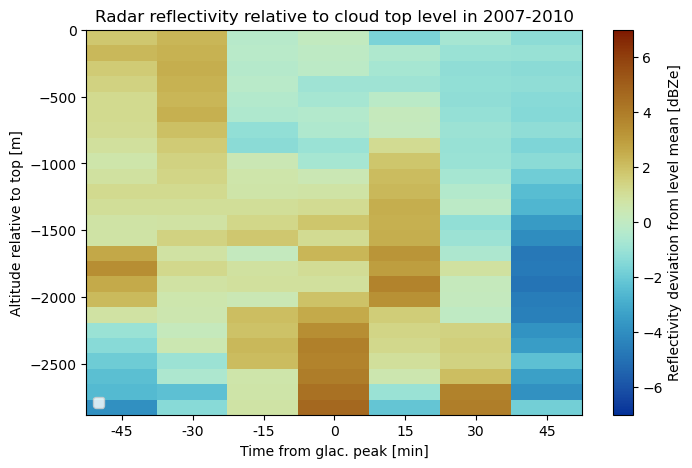

In [108]:
plt.figure(figsize=(8, 5))
plt.imshow(
    dev_vs_others_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-7,
    vmax=7,
    cmap=cm.roma_r
)
# plt.hlines(-ext_lev[1:-1],inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1, label="Cloud top boundary")

plt.xticks(inds, inds * 15)
plt.xlabel("Time from glac. peak [min]")
plt.ylabel("Altitude relative to top [m]")
plt.colorbar(label="Reflectivity deviation from level mean [dBZe]")
plt.title("Radar reflectivity relative to cloud top level in 2007-2010")
plt.legend(loc="lower left")
plt.show()
# plt.savefig()

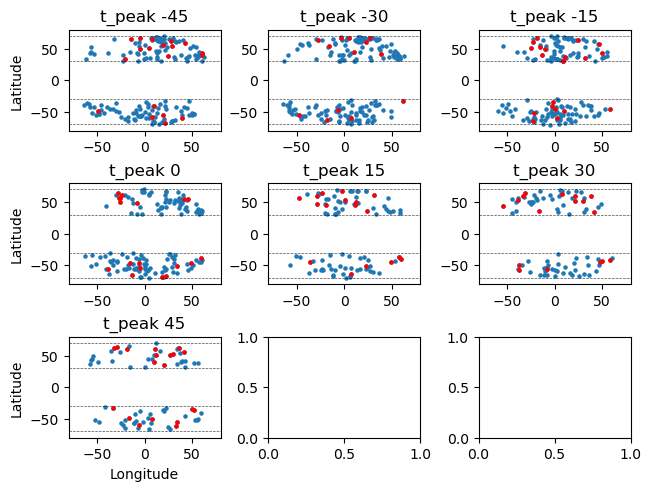

In [109]:
n = len(inds)
nrows = 3
ncols = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, constrained_layout=True)

for i, ind in enumerate(inds):
    row=i//3
    col=i%3
    # print(row,col)
    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds["avg_lon"],selected_clouds["avg_lat"], s=5)
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds_filt["avg_lon"],selected_clouds_filt["avg_lat"],color='red',s=5)
    axes[row,col].set_title(f"t_peak {ind*15}")
    # axes[row,col].set_xscale("log")
    # axes[row,col].set_xlim(0,1e6)
    # axes[row,col].set_ylim(0,40)
    for line_lat in [-70,-30,30,70]:
        axes[row,col].axhline(line_lat,linestyle="--",linewidth=0.5,color="black",alpha=0.7)
    if col==0:
        axes[row,col].set_ylabel("Latitude")
    if row==2:
        axes[row,col].set_xlabel("Longitude")
    axes[row,col].set_ylim(-80,80)
    axes[row,col].set_xlim(-80,80)

plt.show()

/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs

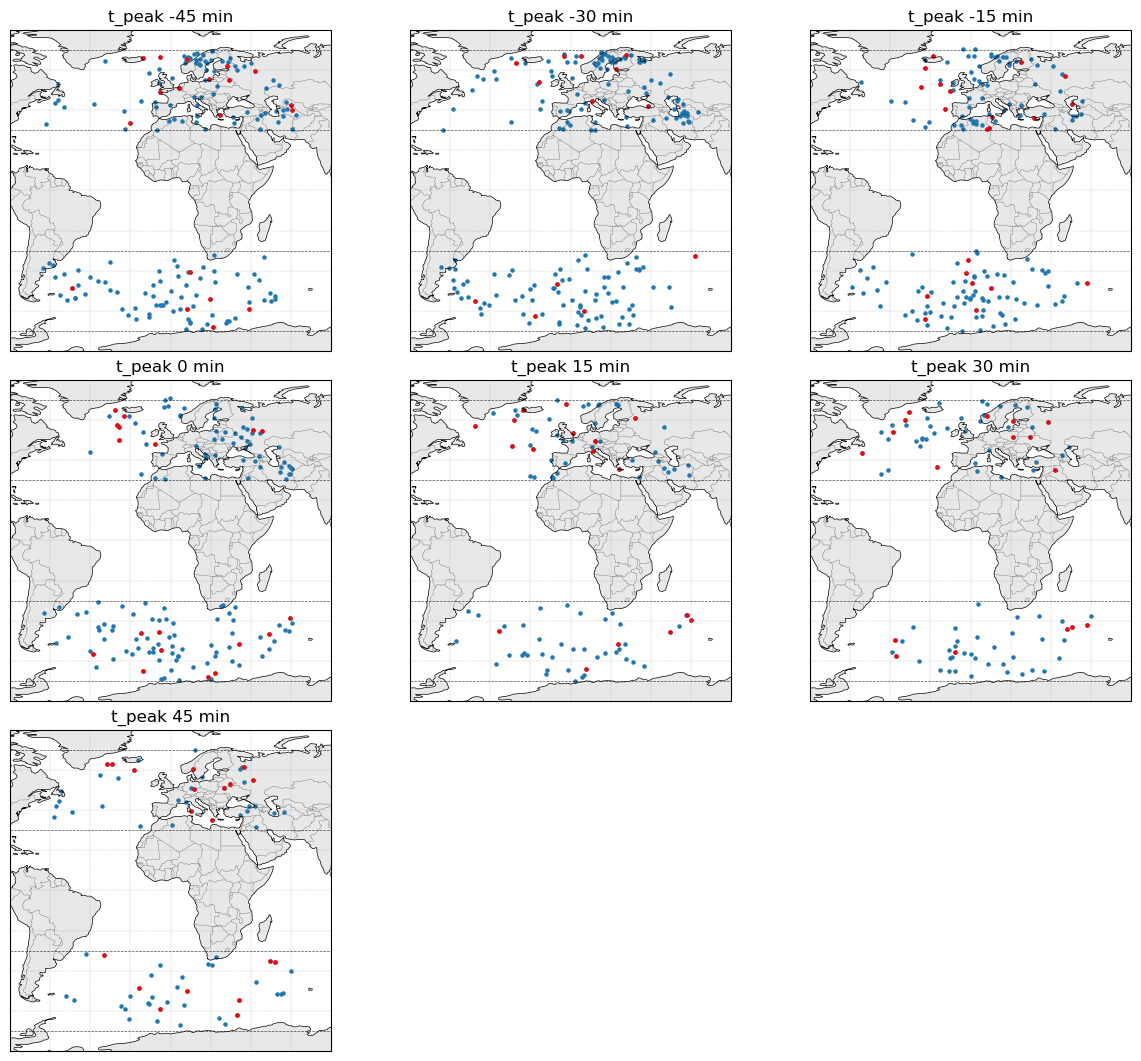

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

n = len(inds)
nrows = 3
ncols = int(np.ceil(n / nrows))

proj = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4 * ncols, 3.5 * nrows),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = np.asarray(axes).reshape(nrows, ncols)

for i, ind in enumerate(inds):
    row = i // ncols
    col = i % ncols
    ax = axes[row, col]

    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"] == ind]
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"] == ind]

    # Map background
    ax.set_extent([-80, 80, -80, 80], crs=proj)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.5)
    ax.add_feature(cfeature.OCEAN, facecolor="white", alpha=0.8)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.5)

    # Optional gridlines
    gl = ax.gridlines(
        crs=proj,
        draw_labels=False,
        linewidth=0.3,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    # Scatter points
    ax.scatter(
        selected_clouds["avg_lon"],
        selected_clouds["avg_lat"],
        s=5,
        transform=proj,
        label="All"
    )

    ax.scatter(
        selected_clouds_filt["avg_lon"],
        selected_clouds_filt["avg_lat"],
        color="red",
        s=5,
        transform=proj,
        label="Filtered"
    )

    ax.set_title(f"t_peak {ind * 15} min")

    # Latitude guide lines
    for line_lat in [-70, -30, 30, 70]:
        ax.plot(
            [-80, 80],
            [line_lat, line_lat],
            linestyle="--",
            linewidth=0.5,
            color="black",
            alpha=0.7,
            transform=proj
        )

    if col == 0:
        ax.set_ylabel("Latitude")

    if row == nrows - 1:
        ax.set_xlabel("Longitude")
    # axes[row,col].axhline(selected_clouds_filt["avg_ctt"].mean()-273.15,linestyle="--",linewidth=0.5,color="red")
    # axes[row,col].axvline(selected_clouds_filt["avg_cot"].mean(),linestyle="--",linewidth=0.5,color="red")

# Hide unused axes
for j in range(n, nrows * ncols):
    row = j // ncols
    col = j % ncols
    axes[row, col].set_visible(False)

plt.show()

/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_1688/3380338885.py:17: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  axes[row,col].set_xlim(0,1e6)


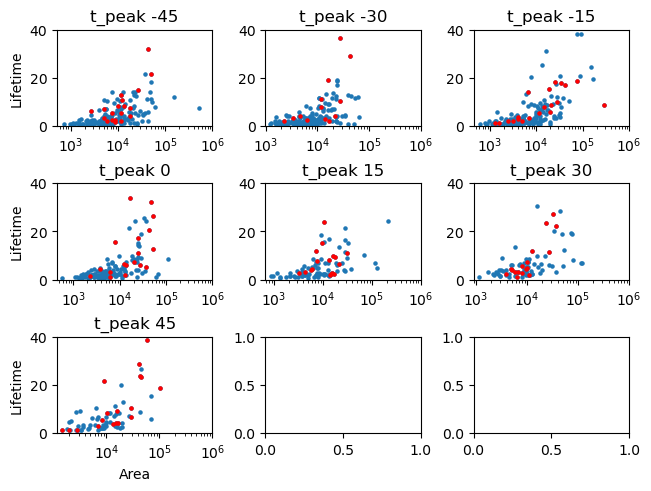

In [111]:
n = len(inds)
nrows = 3
ncols = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, constrained_layout=True)

for i, ind in enumerate(inds):
    row=i//3
    col=i%3
    # print(row,col)
    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds["avg_size[km]"],selected_clouds["Lifetime [h]"], s=5)
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds_filt["avg_size[km]"],selected_clouds_filt["Lifetime [h]"],color='red',s=5)
    axes[row,col].set_title(f"t_peak {ind*15}")
    axes[row,col].set_xscale("log")
    axes[row,col].set_xlim(0,1e6)
    axes[row,col].set_ylim(0,40)
    if col==0:
        axes[row,col].set_ylabel("Lifetime")
    if row==2:
        axes[row,col].set_xlabel("Area")

plt.show()

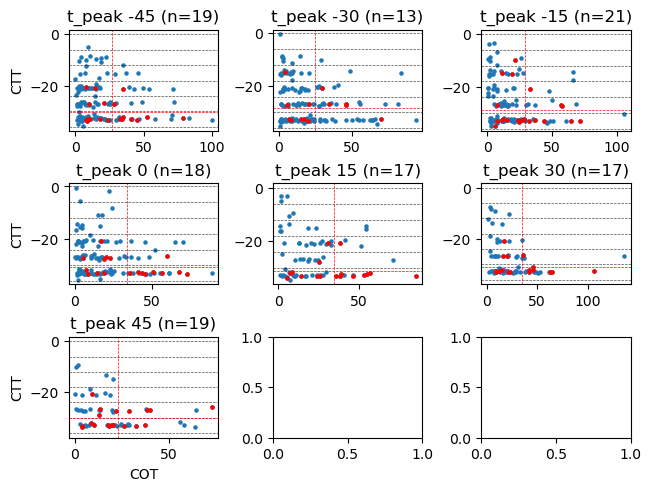

In [112]:
n = len(inds)
nrows = 3
ncols = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, constrained_layout=True)

for i, ind in enumerate(inds):
    row=i//3
    col=i%3
    # print(row,col)
    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds["avg_cot"],selected_clouds["avg_ctt"]-273.15, s=5)
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds_filt["avg_cot"],selected_clouds_filt["avg_ctt"]-273.15,color='red',s=5)
    axes[row,col].set_title(f"t_peak {ind*15} (n={len(selected_clouds_filt)})")
    # axes[row,col].set_xscale("log")
    # axes[row,col].set_xlim(0,1e6)
    # axes[row,col].set_ylim(0,20)
    for bound_temp in range(0,-38,-6):
        axes[row,col].axhline(bound_temp,linestyle="--",linewidth=0.5,color="black",alpha=0.7)
    
    axes[row,col].axhline(selected_clouds_filt["avg_ctt"].mean()-273.15,linestyle="--",linewidth=0.5,color="red")
    axes[row,col].axvline(selected_clouds_filt["avg_cot"].mean(),linestyle="--",linewidth=0.5,color="red")

    if col==0:
        axes[row,col].set_ylabel("CTT")
    if row==2:
        axes[row,col].set_xlabel("COT")

plt.show()

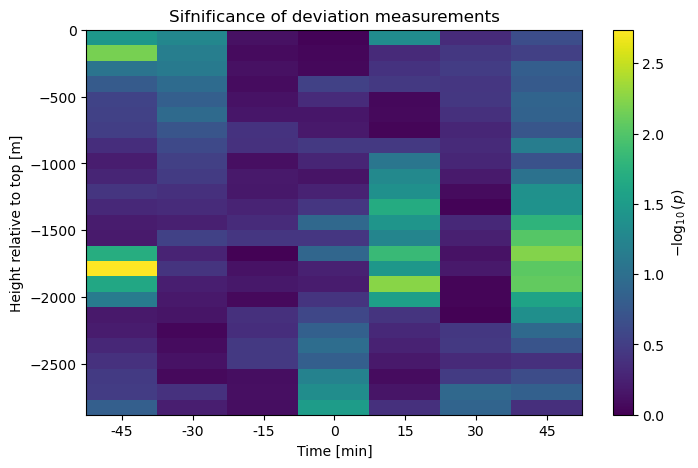

In [113]:
plt.figure(figsize=(8, 5))
sig_map = -np.log10(p_welch_map)
plt.imshow(
    sig_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=0,
)

plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label=r"$-\log_{10}(p)$")
plt.title("Sifnificance of deviation measurements")
plt.show()

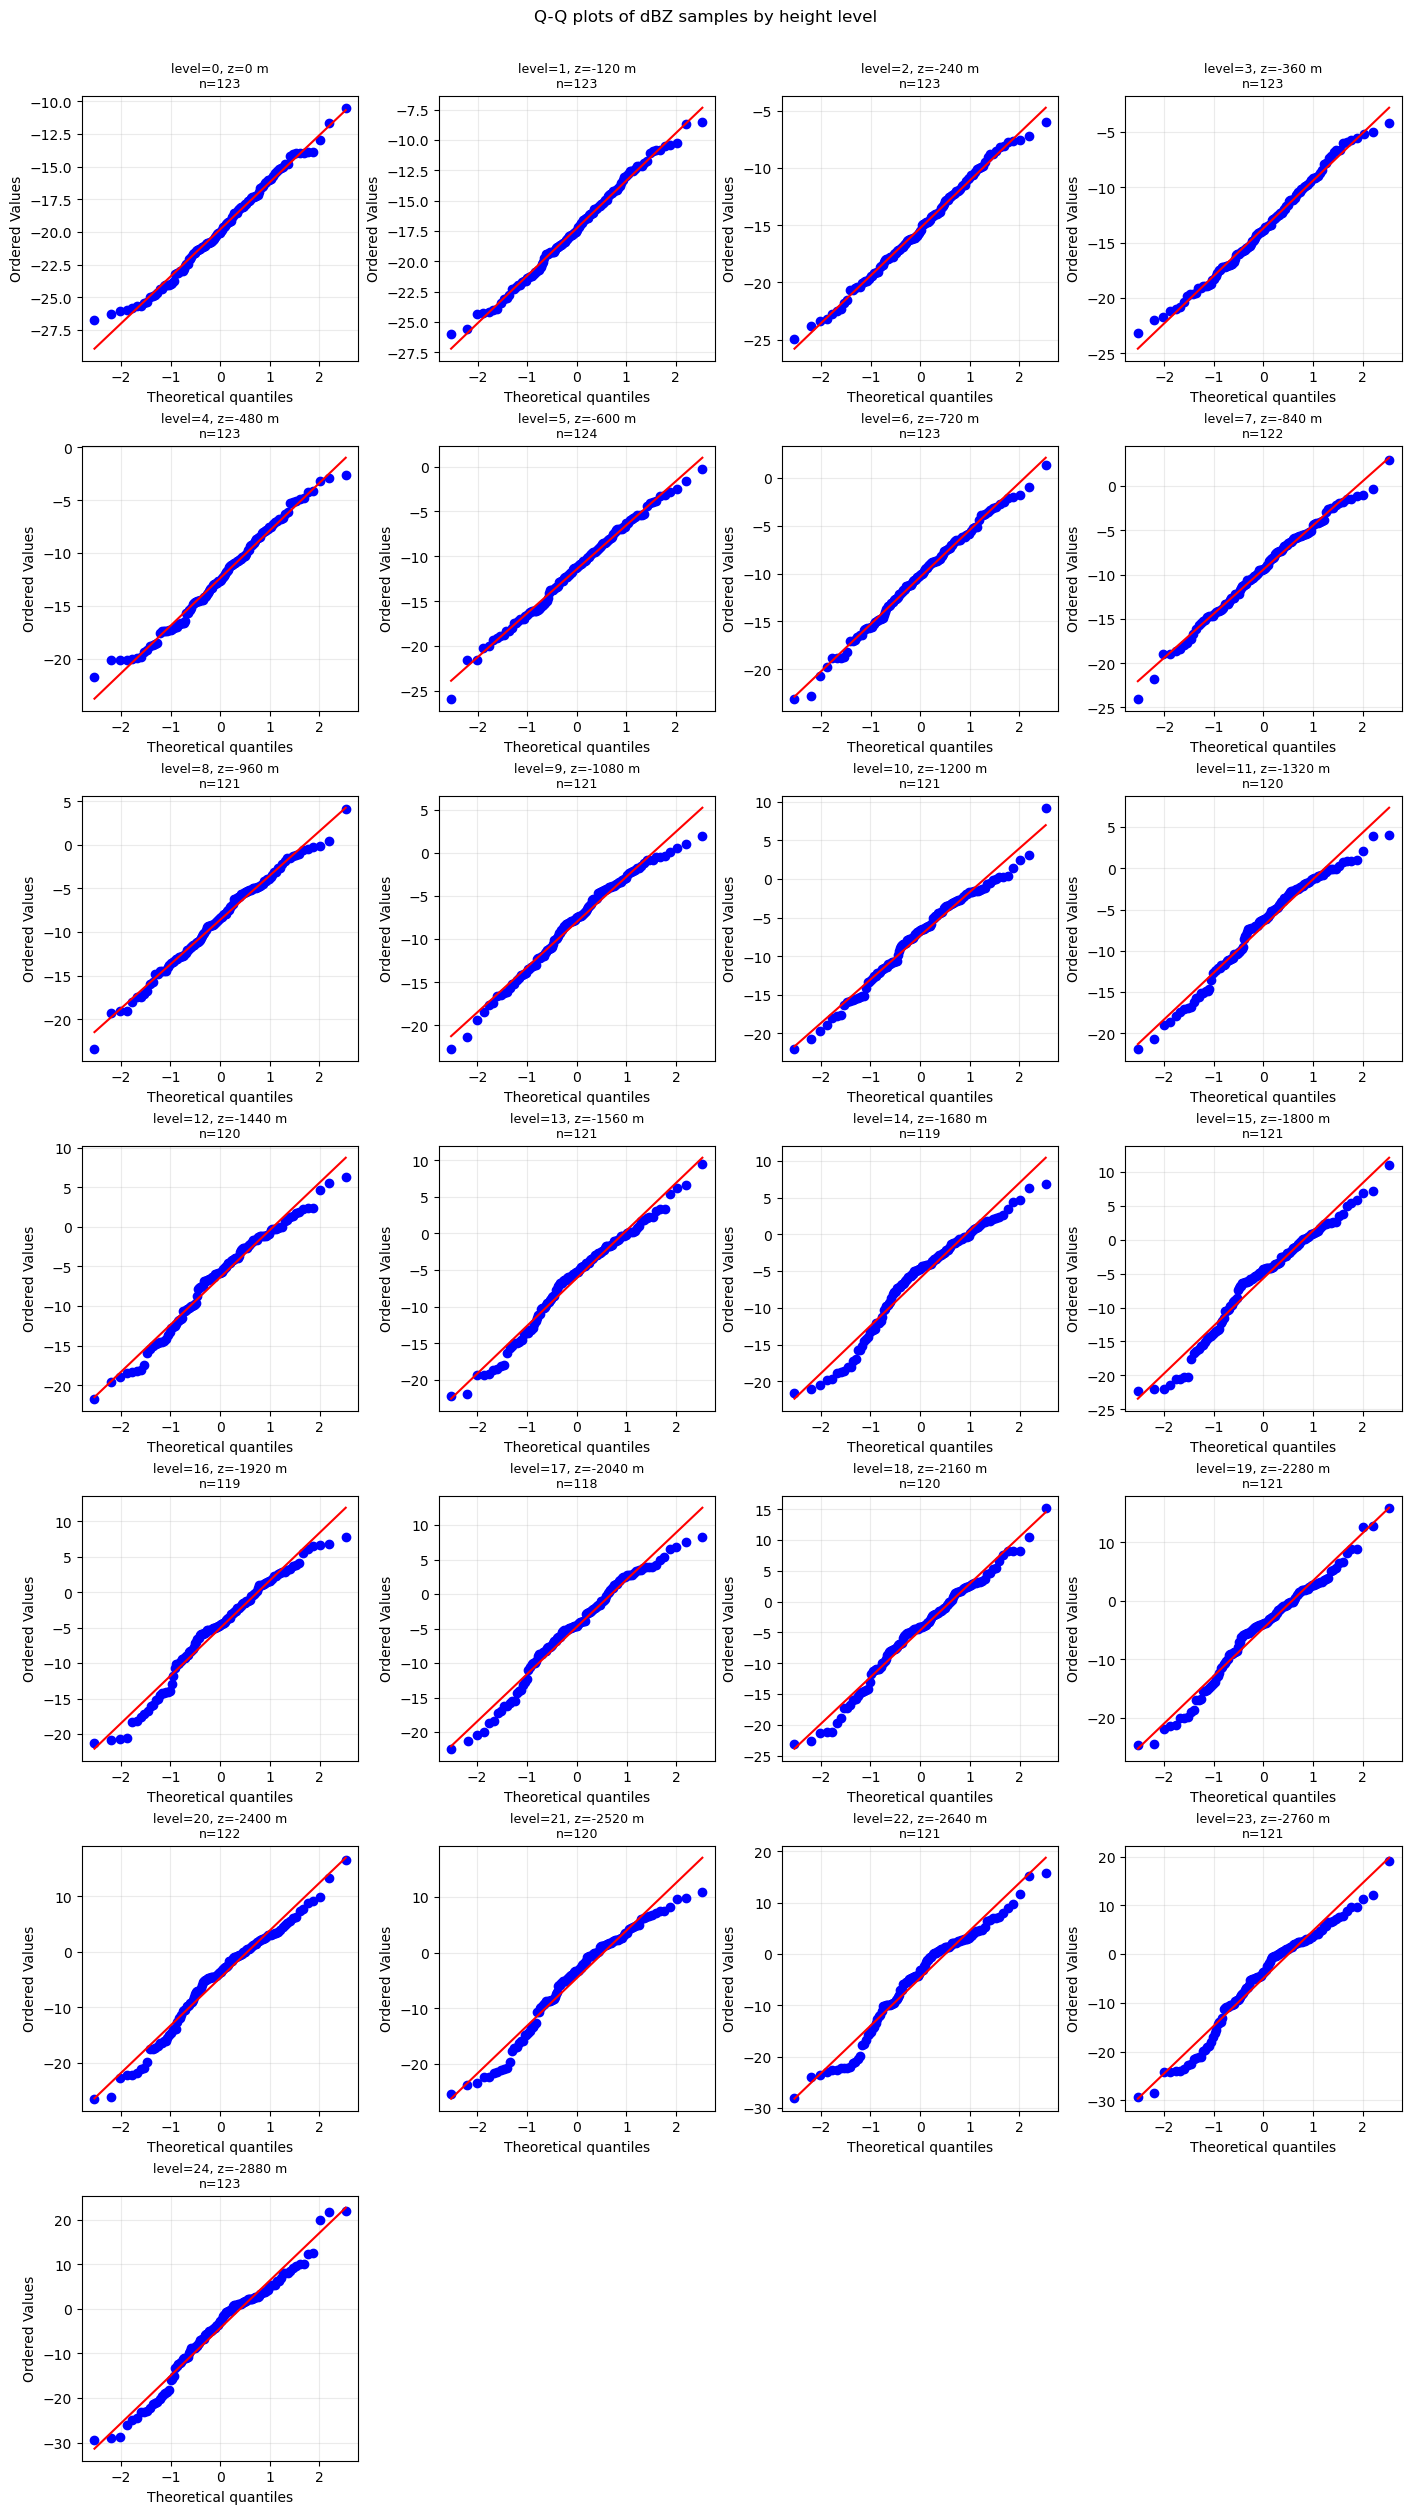

In [114]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

inds = np.arange(ind_range[0], ind_range[1])
n_levels = len(y_levels)

ncols = 4
nrows = int(np.ceil(n_levels / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.5 * ncols, 3.5 * nrows),
    constrained_layout=True
)

axes = np.ravel(axes)

for level, ax in enumerate(axes[:n_levels]):

    level_samples = []

    for ind in inds:
        dbZ = Z_meas[ind]
        dbZ[~np.isfinite(dbZ)] = np.nan

        x = dbZ[:, level]
        x = x[np.isfinite(x)]
        level_samples.append(x)

    x = np.concatenate(level_samples)
    x=remove_outliers_iqr(x)
    if len(x) > 2:
        stats.probplot(x, dist="norm", plot=ax)

    ax.set_title(
        f"level={level}, z={y_levels[level]:.0f} m\nn={len(x)}",
        fontsize=9
    )
    ax.grid(alpha=0.25)

# Hide unused axes
for ax in axes[n_levels:]:
    ax.axis("off")

fig.suptitle("Q-Q plots of dBZ samples by height level", y=1.02)
plt.show()

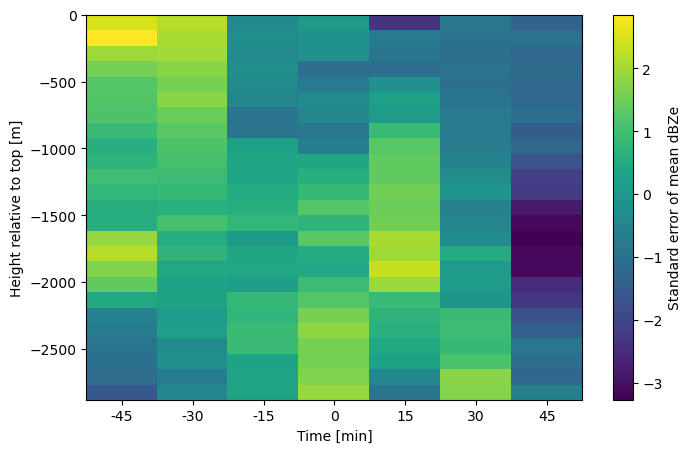

In [115]:
plt.figure(figsize=(8, 5))
plt.imshow(
    dev_vs_others_map / sem_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
)
plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label="Standard error of mean dBZe")
plt.show()

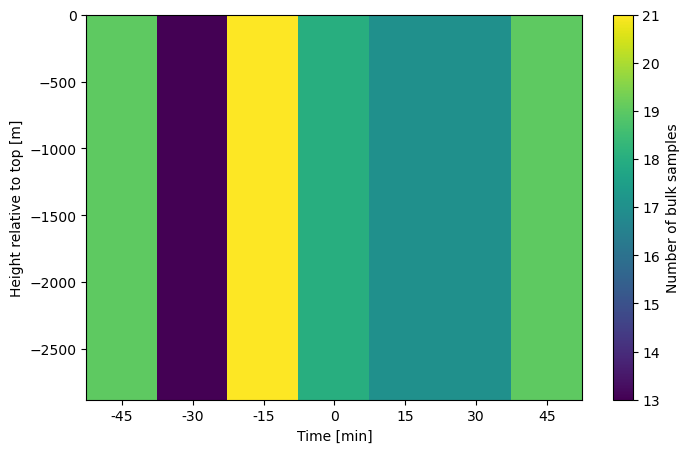

In [116]:
plt.figure(figsize=(8, 5))
plt.imshow(
    n_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    
)
plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label="Number of bulk samples")
plt.show()

(array([0., 0., 0., 9., 5., 8., 4., 4., 4., 2., 4., 1., 2., 2., 4., 0., 1.,
        4., 2., 2., 0., 2., 0., 1., 0., 0., 1., 0., 0., 0., 0., 1., 0., 0.,
        0., 0., 0., 1., 0.]),
 array([-0.25,  0.25,  0.75,  1.25,  1.75,  2.25,  2.75,  3.25,  3.75,
         4.25,  4.75,  5.25,  5.75,  6.25,  6.75,  7.25,  7.75,  8.25,
         8.75,  9.25,  9.75, 10.25, 10.75, 11.25, 11.75, 12.25, 12.75,
        13.25, 13.75, 14.25, 14.75, 15.25, 15.75, 16.25, 16.75, 17.25,
        17.75, 18.25, 18.75, 19.25]),
 <BarContainer object of 39 artists>)

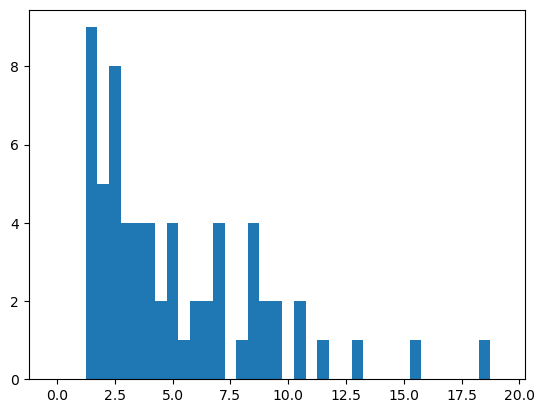

In [117]:
plt.hist(selected_clouds["track_length"]/pd.Timedelta(hours=1),bins=np.arange(0,40)/2-0.25)

In [118]:
def calculate_top_depth(row):
    tot_thickness = 0
    small_ext_counter = 0
    for j, ext in enumerate(row["ext_bulk_means"]):
        lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
        tot_thickness += lev_depth*ext
        if ext<2.0e-4:
            small_ext_counter+=1
        if tot_thickness>=0.2:
            # print(tot_thickness,j*120,small_ext_counter*120)
            return j*120
    return None
        
            
sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [119]:
(sample["ct_depth"]>600).value_counts()

ct_depth
False    69
True     31
Name: count, dtype: int64

In [120]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.2):
    tau = optical_depth_path(row)["tau"]
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    return top_idx*120

In [121]:
# Calculate total optical depth per cloud 
bulk_data_df_split["2km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4).all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_top_depth,axis=1)

In [122]:
bulk_data_df_split["ct_depth"].isna().value_counts()

ct_depth
False    3611
True      814
Name: count, dtype: int64

In [123]:
bulk_data_df_split.iloc[0]["val_cth_hist"]

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00,  3.39187398e+03, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00])

In [124]:
ALLOWED_CTH_DEV=1000
def _check_val_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    target_ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if not points_of_interest[target_ind]:
        print("weird")
        return False
    if type(row["cth_hist"]) == float:
            # N+=1
            return False
    cth_deviation = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # cth_deviations = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # if cth_deviations.size == 0:
    #     return False
    # mean_height_dev = cth_deviations.mean()  
    # if mean_height_dev > ALLOWED_CTH_DEV:
    #     return False
    if cth_deviation > ALLOWED_CTH_DEV:
        return False
    return True


In [125]:
bulk_data_df_split["val_seviri_coincidence"] = bulk_data_df_split.apply(_check_val_seviri_coincidence,axis=1)

In [126]:
bulk_data_df_split["val_seviri_coincidence"].value_counts()

val_seviri_coincidence
True     2772
False    1653
Name: count, dtype: int64

In [127]:
# print(np.argmax(optical_depth_path(bulk_data_filtered.iloc[0])["tau"]>0.3))
# print(optical_depth_path(bulk_data_filtered.iloc[0])["tau"])

<Figure size 700x500 with 0 Axes>

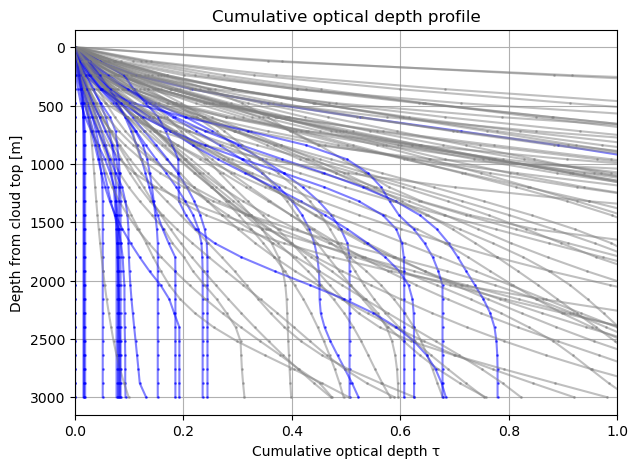

In [128]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt




plt.figure(figsize=(7, 5))

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path(row)

    if p is None:
        continue
    if ((p["tau"][1:]-p["tau"][:-1])<5*1e-4).any():
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="blue",
            markersize=1
        )
    else:
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="gray",
            markersize=1
        )



# plt.axvline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Cumulative optical depth τ")
plt.ylabel("Depth from cloud top [m]")
plt.title("Cumulative optical depth profile")
plt.grid(True)
plt.xlim(0, 1)

# Optional: depth increasing downward
plt.gca().invert_yaxis()

plt.show()

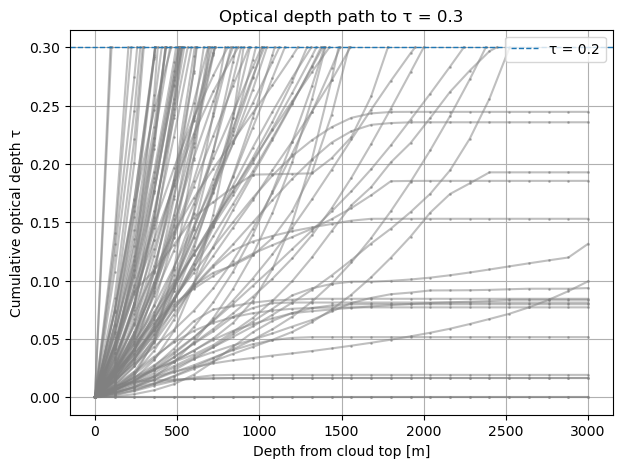

In [129]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

def optical_depth_path_to_03(row, tau_target=0.3):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext_profile = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    if len(dz) != len(ext_profile):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, "
            f"extinction has {len(ext_profile)} values"
        )

    tau = 0.0
    depth = 0.0

    depth_path = [0.0]
    tau_path = [0.0]

    for layer_dz, ext in zip(dz, ext_profile):
        layer_tau = layer_dz * ext

        # if tau_target is reached inside this layer, interpolate
        if tau + layer_tau >= tau_target:
            remaining_tau = tau_target - tau

            if ext > 0:
                depth_inside_layer = remaining_tau / ext
            else:
                depth_inside_layer = layer_dz

            depth += depth_inside_layer
            tau = tau_target

            depth_path.append(depth)
            tau_path.append(tau)
            break

        tau += layer_tau
        depth += layer_dz

        depth_path.append(depth)
        tau_path.append(tau)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path),
        "reached_03": tau >= tau_target
    }

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path_to_03(row, tau_target=0.3)

    if p is None:
        continue

    plt.plot(
        p["depth_m"],
        p["tau"],
        alpha=0.5,
        marker="o",
        color="gray",
        markersize=1
    )

plt.axhline(0.3, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Depth from cloud top [m]")
plt.ylabel("Cumulative optical depth τ")
plt.title("Optical depth path to τ = 0.3")
plt.grid(True)
plt.legend()
plt.show()

In [130]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
    row["lat_hist"],
    row["lat_hist"]
),axis=1)
bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [131]:
# Filter only for clouds that survive after glaciation
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split["val_seviri_coincidence"]]
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["2km_cot"]>0.3]
# Select only one pass where 2 are available
bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
# Filter for cloud type
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# Remove clouds outside measurement boundaries
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,rel_ind,rel_time_min,2km_cot,continious_cloud,ct_depth,surface_type,is_maritime
3,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",35,525,8.703243,True,0.0,"[maritime, maritime, maritime, maritime, marit...",True
5,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",82,1230,1.340141,True,120.0,"[maritime, maritime, maritime, maritime, marit...",True
7,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-17,-255,4.366257,True,240.0,"[maritime, maritime, maritime, maritime, marit...",True
10,83077,690,0.452658,10,56,False,0.188522,"[0.048405932671319776, 0.09078118270939935, 0....",0.131825,11.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-34,-510,5.110668,True,240.0,"[land, land, land, land, land, land, land, lan...",False
17,106589,60,0.521698,63,67,False,0.142036,"[0.3393176823442888, 0.5477031707440038, 0.640...",0.469096,1.00,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-53,-795,1.580397,True,1080.0,"[maritime, maritime, maritime, maritime, marit...",True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4731,3946060,2115,0.770868,0,141,False,0.176908,"[0.3326430852169193, 0.5987685460219256, 0.550...",0.085207,35.25,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-98,-1470,2.619733,True,480.0,"[maritime, maritime, maritime, maritime, marit...",True
4739,3947705,105,0.496095,20,27,False,0.144165,"[0.7338413328330609, 0.7611625173449219, 0.761...",0.752055,1.75,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-13,-195,0.384368,True,1800.0,"[maritime, maritime, maritime, maritime, marit...",True
4741,3948854,1050,0.610622,15,85,True,0.088805,"[0.03489266123090472, 0.03489266123090472, 0.0...",0.034893,17.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",21,315,1.322223,True,1200.0,"[maritime, maritime, maritime, maritime, marit...",True
4745,3949077,330,0.715548,53,75,False,0.116834,"[0.149197767779818, 0.1785295182082949, 0.1848...",0.179550,5.50,...,"[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",-33,-495,1.156891,True,960.0,"[maritime, maritime, maritime, maritime, marit...",False


## Z_Meas

In [132]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    iwc_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        iwc_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["iwc_bulk_means"].to_numpy())
        ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas, t_meas, ext_meas, iwc_meas

Z_meas, t_meas, ext_meas, iwc_meas = extract_bulk_samples_by_time(bulk_data_filtered)
